# Laboratorul 7 — Support Vector Machines și nuclee
**Student:** Trandafir Florin-Daniel, IASD 2601

Rezolvarea tuturor celor patru exerciții. Ținta clasificării este **culoarea
vinului**: 1 = roșu, 0 = alb. Rulați celulele în ordine, cu Pythonul local.
Fișierul `Wine_Quality_Data.csv` trebuie să fie în același folder cu notebookul.
Biblioteci: NumPy, pandas, Matplotlib, seaborn, scikit-learn, IPython.

# Obiectivele cursului
- Aplicarea metodei vectorilor de suport (SVM) — un algoritm popular utilizat pentru sarcini de clasificare
- Recunoașterea similitudinii dintre SVM și regresia logistică
- Calcularea funcției de pierdere pentru SVM
- Aplicarea regularizării în SVM și studierea recomandărilor privind obținerea unei clasificări neliniare cu ajutorul SVM

## Introducere
În aceste exerciții vom folosi un set de date privind calitatea vinului. Acest set de date conține diverse proprietăți chimice ale vinului, precum aciditatea, conținutul de zahăr, pH-ul și conținutul de alcool. De asemenea, conține o măsură a calității (de la 3 la 9, unde scorul cel mai mare indică cea mai bună calitate) și culoarea (roșu sau alb). Numele fișierului: `Wine_Quality_Data.csv`.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display
from matplotlib.lines import Line2D
from sklearn.svm import LinearSVC, SVC
from sklearn.kernel_approximation import Nystroem
from sklearn.linear_model import SGDClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, hinge_loss
from threadpoolctl import threadpool_limits

RANDOM_STATE = 42
DATA_PATH = Path('Wine_Quality_Data.csv')
sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.dpi': 100, 'axes.titlesize': 12})
print('Python:', sys.version.split()[0])
print('Executabil:', sys.executable)
print('scikit-learn:', sklearn.__version__)

Python: 3.11.1
Executabil: /Library/Frameworks/Python.framework/Versions/3.11/bin/python3
scikit-learn: 1.9.1


## Întrebarea 1
* Importul datelor.
* Creați variabila țintă `y` sub forma unei coloane cu valori 1/0, unde 1 înseamnă vin roșu.
* Creați un grafic pereche pentru setul de date.
* Creați un grafic cu bare care să ilustreze corelația dintre fiecare coloană și `y`.
* Selectați cele două câmpuri cu cea mai mare corelație (folosind valorile corelației absolute) și creați `X`.
* Folosiți MinMaxScaler pentru a scala `X`. Rețineți că rezultatul va fi un np.array. Transformați-l din nou într-un DataFrame și redenumiți coloanele în consecință.

In [2]:
data = pd.read_csv(DATA_PATH)
assert set(data['color'].unique()) == {'red', 'white'}
assert not data.isna().any().any(), 'Setul conține valori lipsă.'
y = data['color'].map({'red': 1, 'white': 0}).astype('int64').rename('y')
numeric_features = data.drop(columns='color')
assert all(pd.api.types.is_numeric_dtype(t) for t in numeric_features.dtypes)
print(f'Dimensiune: {data.shape[0]} observații, {data.shape[1]} coloane.')
display(data.head())
display(y.value_counts().rename(index={0: 'alb (0)', 1: 'roșu (1)'}).to_frame('număr'))
display(numeric_features.describe().round(3))

Dimensiune: 6497 observații, 13 coloane.


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,color
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


,număr
y,
alb (0),4898
roșu (1),1599


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality
count,6497.000,6497.000,6497.000,6497.000,6497.000,6497.000,6497.000,6497.000,6497.000,6497.000,6497.000,6497.000
mean,7.215,0.340,0.319,5.443,0.056,30.525,115.745,0.995,3.219,0.531,10.492,5.818
std,1.296,0.165,0.145,4.758,0.035,17.749,56.522,0.003,0.161,0.149,1.193,0.873
min,3.800,0.080,0.000,0.600,0.009,1.000,6.000,0.987,2.720,0.220,8.000,3.000
25%,6.400,0.230,0.250,1.800,0.038,17.000,77.000,0.992,3.110,0.430,9.500,5.000
50%,7.000,0.290,0.310,3.000,0.047,29.000,118.000,0.995,3.210,0.510,10.300,6.000
75%,7.700,0.400,0.390,8.100,0.065,41.000,156.000,0.997,3.320,0.600,11.300,6.000
max,15.900,1.580,1.660,65.800,0.611,289.000,440.000,1.039,4.010,2.000,14.900,9.000


### Grafic pereche
Folosim toate observațiile și cele 12 variabile numerice, inclusiv `quality`.
Triunghiul inferior evită repetarea acelorași perechi. Culoarea indică ținta;
`y` nu este inclus printre variabilele explicative.

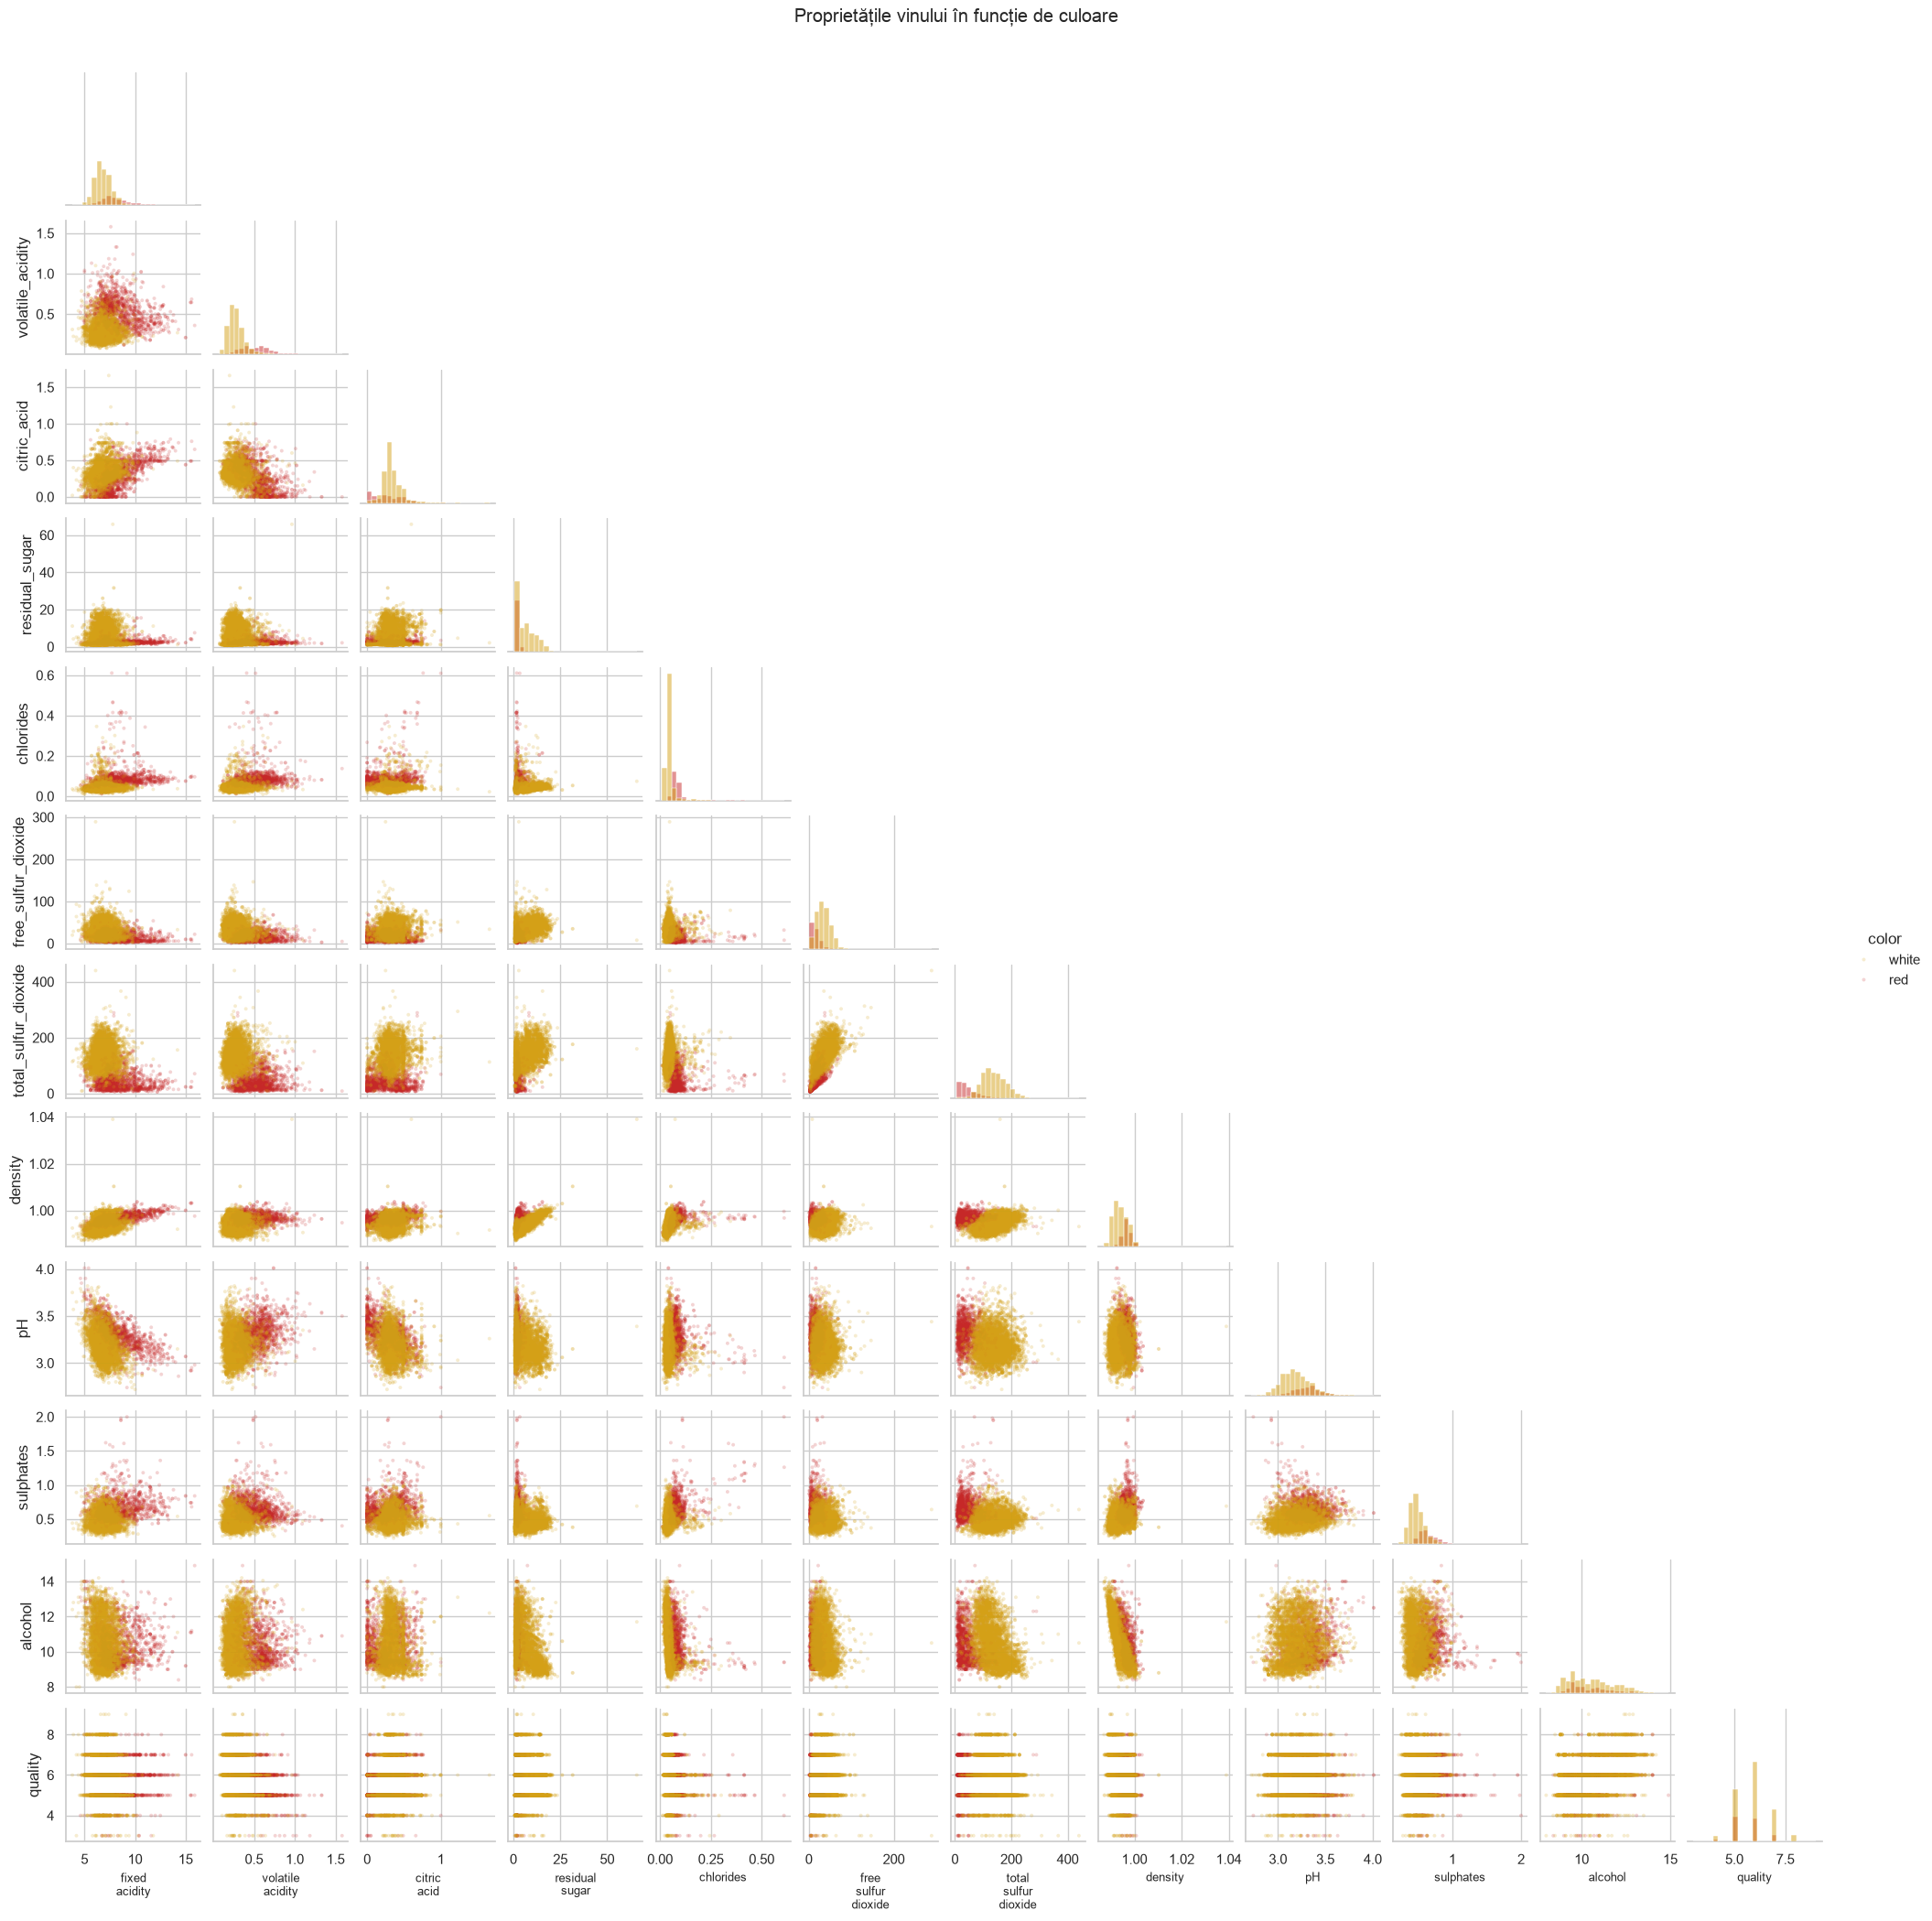

In [3]:
pair_grid = sns.pairplot(
    data, vars=numeric_features.columns.tolist(), hue='color',
    hue_order=['white', 'red'], palette={'white': '#d4a017', 'red': '#c62828'},
    corner=True, diag_kind='hist', height=1.7,
    plot_kws={'s': 8, 'alpha': 0.2, 'linewidth': 0, 'rasterized': True},
    diag_kws={'bins': 25, 'alpha': 0.5},
)
for ax in pair_grid.axes[-1, :]:
    if ax is not None:
        ax.set_xlabel(ax.get_xlabel().replace('_', '\n'), fontsize=9)
pair_grid.figure.suptitle('Proprietățile vinului în funcție de culoare', y=1.02)
plt.show()

,corelație cu y
total_sulfur_dioxide,-0.700357
volatile_acidity,0.653036
chlorides,0.512678
sulphates,0.487218
fixed_acidity,0.486740
free_sulfur_dioxide,-0.471644
density,0.390645
residual_sugar,-0.348821
pH,0.329129
citric_acid,-0.187397


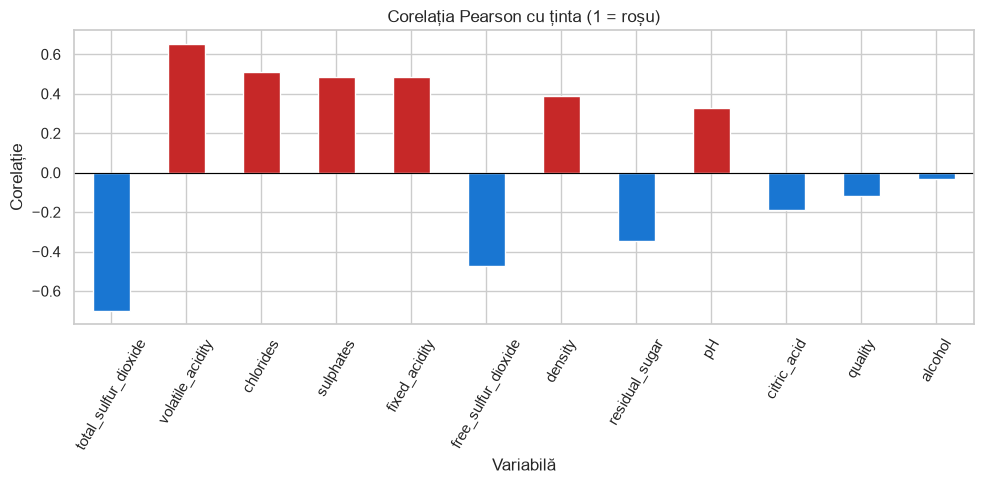

Variabilele selectate: ['total_sulfur_dioxide', 'volatile_acidity']


,total_sulfur_dioxide,volatile_acidity
0,0.064516,0.413333
1,0.140553,0.533333
2,0.110599,0.453333
3,0.124424,0.133333
4,0.064516,0.413333


In [4]:
correlations = numeric_features.corrwith(y)
feature_order = correlations.abs().sort_values(ascending=False).index
correlations = correlations.loc[feature_order]
display(correlations.rename('corelație cu y').to_frame())
fig, ax = plt.subplots(figsize=(10, 5))
correlations.plot.bar(ax=ax, color=np.where(correlations >= 0, '#c62828', '#1976d2'))
ax.axhline(0, color='black', linewidth=0.8)
ax.set(title='Corelația Pearson cu ținta (1 = roșu)', ylabel='Corelație', xlabel='Variabilă')
ax.tick_params(axis='x', rotation=60)
fig.tight_layout()
plt.show()

selected_features = feature_order[:2].tolist()
X_raw = numeric_features[selected_features].copy()
scaler = MinMaxScaler()
X = pd.DataFrame(scaler.fit_transform(X_raw), columns=selected_features, index=data.index)
assert X.index.equals(y.index)
assert np.allclose(X.min(), 0) and np.allclose(X.max(), 1)
print('Variabilele selectate:', selected_features)
display(X.head())

**Interpretare.** Cele mai mari corelații absolute cu ținta sunt pentru
`total_sulfur_dioxide` (negativă) și `volatile_acidity` (pozitivă).
O corelație negativă puternică poate fi la fel de utilă ca una pozitivă.
MinMaxScaler aplică $x'=(x-\min(x))/(\max(x)-\min(x))$.

Exercițiile 1–3 explorează frontierele pe întregul set, conform cerinței.
Selecția, scalarea și antrenarea folosesc toate datele; scorurile afișate sunt
**de antrenare**, nu estimări ale generalizării. Pentru o evaluare predictivă
trebuie separat un set de test înainte de selecție și scalare.

## Întrebarea 2

Scopul acestei întrebări este de a analiza pragul de decizie al clasificatorului LinearSVC pentru setul de date dat. Consultați [acest exemplu](http://scikit-learn.org/stable/auto_examples/svm/plot_iris.html#sphx-glr-auto-examples-svm-plot-iris-py) din documentația sklearn.

* Configurați clasificatorul LinearSVC pe `X` și `y`.
* Selectați 300 de eșantioane din `X`. Obțineți valorile corespunzătoare ale `y`. Salvați-le în variabilele `X_color` și `y_color`. Acest lucru se datorează faptului că setul de date original este prea mare și generează un grafic supraîncărcat.
* Modificați `y_color` astfel încât valoarea „roșu” să înlocuiască 1, iar „galben” să înlocuiască 0.
* Graficul de dispersie pentru coloanele X_color. Utilizați argumentul cu cuvântul-cheie „color=y_color” pentru a afișa codul culorii.
* Utilizați fragmentul de cod de mai jos pentru a desena suprafața soluției în culori.


python

x_axis, y_axis = np.arange(0, 1, .005), np.arange(0, 1, .005)

xx, yy = np.meshgrid(x_axis, y_axis)

xx_ravel = xx.ravel()

yy_ravel = yy.ravel()

X_grid = pd.DataFrame([xx_ravel, yy_ravel]). T

y_grid_predictions = *[MODELUL DVS.]*. predict(X_grid)

y_grid_predictions = y_grid_predictions.reshape(xx.shape)

ax.contourf(xx, yy, y_grid_predictions, cmap=plt.cm.autumn_r, alpha=.3)


Nu ezitați să experimentați cu diferite variante de parametri pentru LinearSVC și să examinați marginile de decizie.

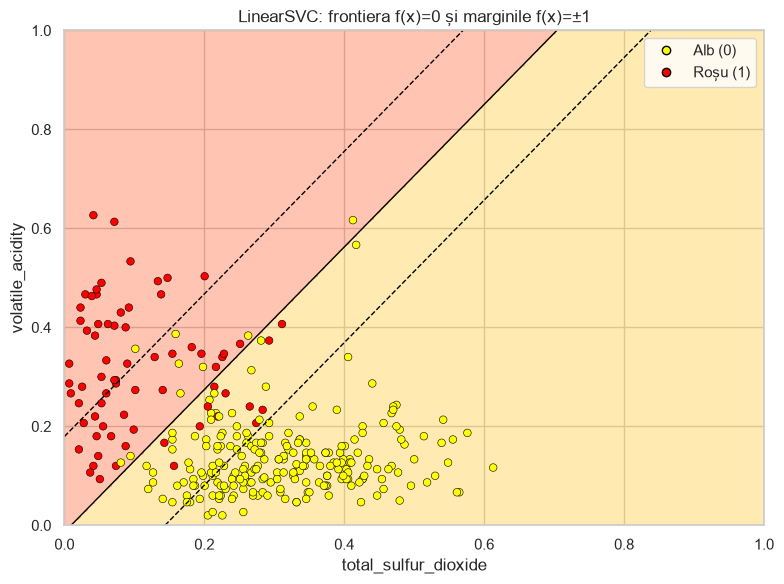

Acuratețe pe antrenare: 0.9546
Coeficienți: {'total_sulfur_dioxide': np.float64(-7.453853569888083), 'volatile_acidity': np.float64(5.1746369820524265)}
Intercept: 0.0717
Pierderea hinge medie: 0.1720


In [5]:
linear_model = LinearSVC(C=1.0, dual=False, max_iter=20000, random_state=RANDOM_STATE)
linear_model.fit(X, y)
X_color = X.sample(n=300, random_state=RANDOM_STATE)
y_sample = y.loc[X_color.index]
y_color = y_sample.map({1: 'red', 0: 'yellow'})
# Matplotlib folosește red/yellow pentru roșu/galben.
assert X_color.index.equals(y_color.index)

x_axis, y_axis = np.arange(0, 1.005, 0.005), np.arange(0, 1.005, 0.005)
xx, yy = np.meshgrid(x_axis, y_axis)
X_grid = pd.DataFrame(np.c_[xx.ravel(), yy.ravel()], columns=X.columns)
y_grid_predictions = linear_model.predict(X_grid).reshape(xx.shape)
decision_values = linear_model.decision_function(X_grid).reshape(xx.shape)
fig, ax = plt.subplots(figsize=(8, 6))
ax.contourf(xx, yy, y_grid_predictions, levels=[-0.5, 0.5, 1.5], cmap=plt.cm.autumn_r, alpha=0.3)
ax.contour(xx, yy, decision_values, levels=[-1, 0, 1], colors='black',
           linestyles=['--', '-', '--'], linewidths=1)
ax.scatter(X_color.iloc[:, 0], X_color.iloc[:, 1], color=y_color,
           edgecolor='black', linewidth=0.4, s=30)
class_legend = [
    Line2D([0], [0], marker='o', linestyle='', markerfacecolor='yellow', markeredgecolor='black', label='Alb (0)'),
    Line2D([0], [0], marker='o', linestyle='', markerfacecolor='red', markeredgecolor='black', label='Roșu (1)'),
]
ax.legend(handles=class_legend, loc='upper right')
ax.set(xlabel=X.columns[0], ylabel=X.columns[1], xlim=(0, 1), ylim=(0, 1),
       title='LinearSVC: frontiera f(x)=0 și marginile f(x)=±1')
fig.tight_layout()
plt.show()
print(f'Acuratețe pe antrenare: {accuracy_score(y, linear_model.predict(X)):.4f}')
print('Coeficienți:', dict(zip(X.columns, linear_model.coef_[0])))
print(f'Intercept: {linear_model.intercept_[0]:.4f}')
y_signed = 2 * y.to_numpy() - 1
scores = linear_model.decision_function(X)
manual_hinge = np.maximum(0, 1 - y_signed * scores).mean()
assert np.isclose(manual_hinge, hinge_loss(y, scores))
print(f'Pierderea hinge medie: {manual_hinge:.4f}')

**Interpretare.** Frontiera liniară este dreapta $f(x)=w^Tx+b=0$;
liniile întrerupte indică marginile $f(x)=\pm1$.
Pentru $t\in\{-1,+1\}$, pierderea hinge este $\max(0,1-tf(x))$.
Calculul de mai sus ilustrează hinge; implicit LinearSVC optimizează
**squared hinge**, cu regularizare L2.
`C` mai mare penalizează mai mult încălcarea marginilor; `C` mai mic înseamnă
regularizare mai puternică. Regresia logistică folosește tot un scor liniar,
dar o pierdere logistică și produce probabilități.

## Întrebarea 3

Să extindem acum nucleul Gauss al SVC și să vedem cum se modifică limita de decizie.

* Combinați fragmentele de cod din întrebarea 2 într-o singură funcție, care utilizează estimatorul `X` și `y` și va genera graficul final cu limita de decizie. Pași:
    <ol>
     <li> modelul potrivit
     <li> obțineți un eșantion de 300 de înregistrări din X și valorile corespunzătoare ale lui y
     <li> creați o rețea, faceți predicții, generați un grafic folosind ax.contourf
     <li> adăugați-l la graficul dispersat
    </ol>
* După copierea și inserarea codului, asigurați-vă că funcția finală utilizează `estimatorul` dvs. de intrare, nu modelul LinearSVC creat de dvs.
* Pentru următoarele valori ale lui `gamma`, creați un SVC cu kernel gaussian și desenați curba de decizie.
`gammas = [.5, 1, 2, 10]`
* Menținând `gamma` constantă, pentru diferite valori ale lui `C`, desenați curba de decizie. Puteți încerca
`Cs = [.1, 1, 10]>

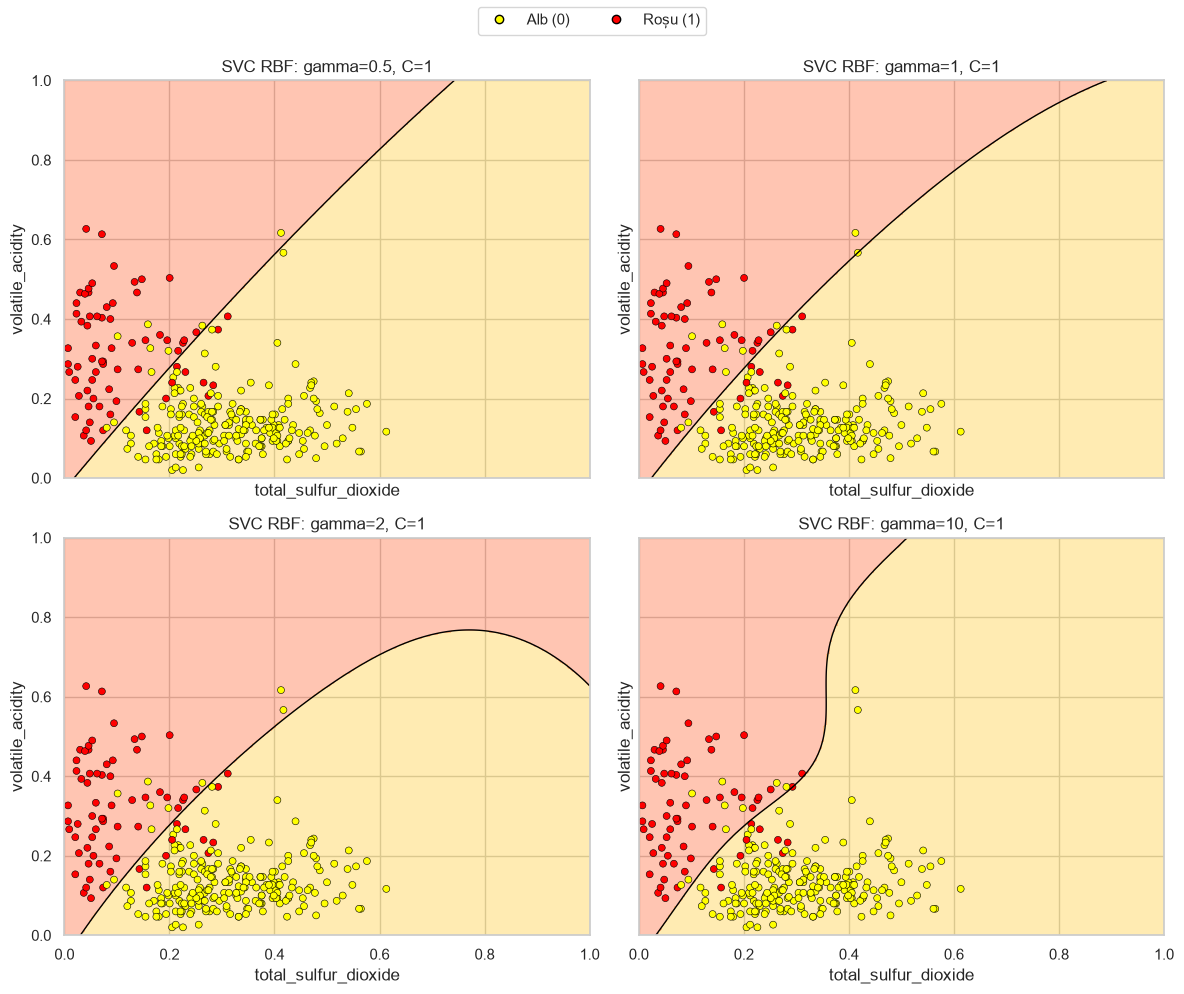

In [6]:
def plot_decision_boundary(estimator, X, y, ax=None, title=None):
    """Antrenează estimatorul primit și desenează frontiera pe două variabile scalate."""
    if X.shape[1] != 2 or not X.index.equals(y.index):
        raise ValueError('Sunt necesare două coloane și indici X/y aliniați.')
    estimator.fit(X, y)
    X_color = X.sample(n=min(300, len(X)), random_state=RANDOM_STATE)
    y_color = y.loc[X_color.index].map({1: 'red', 0: 'yellow'})
    axis = np.arange(0, 1.005, 0.005)
    xx, yy = np.meshgrid(axis, axis)
    grid = pd.DataFrame(np.c_[xx.ravel(), yy.ravel()], columns=X.columns)
    predictions = estimator.predict(grid).reshape(xx.shape)
    decision = estimator.decision_function(grid).reshape(xx.shape)
    if ax is None:
        _, ax = plt.subplots(figsize=(7, 5))
    ax.contourf(xx, yy, predictions, levels=[-0.5, 0.5, 1.5], cmap=plt.cm.autumn_r, alpha=0.3)
    ax.contour(xx, yy, decision, levels=[0], colors='black', linewidths=1)
    ax.scatter(X_color.iloc[:, 0], X_color.iloc[:, 1], color=y_color,
               edgecolor='black', linewidth=0.4, s=25)
    ax.set(xlabel=X.columns[0], ylabel=X.columns[1], xlim=(0, 1), ylim=(0, 1),
           title=title or type(estimator).__name__)
    return estimator

gammas = [0.5, 1, 2, 10]
gamma_models = {}
fig, axes = plt.subplots(2, 2, figsize=(12, 10), sharex=True, sharey=True)
for ax, gamma in zip(axes.flat, gammas):
    gamma_models[gamma] = plot_decision_boundary(
        SVC(kernel='rbf', gamma=gamma, C=1.0), X, y, ax=ax,
        title=f'SVC RBF: gamma={gamma}, C=1')
fig.legend(handles=class_legend, loc='upper center', ncol=2)
fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

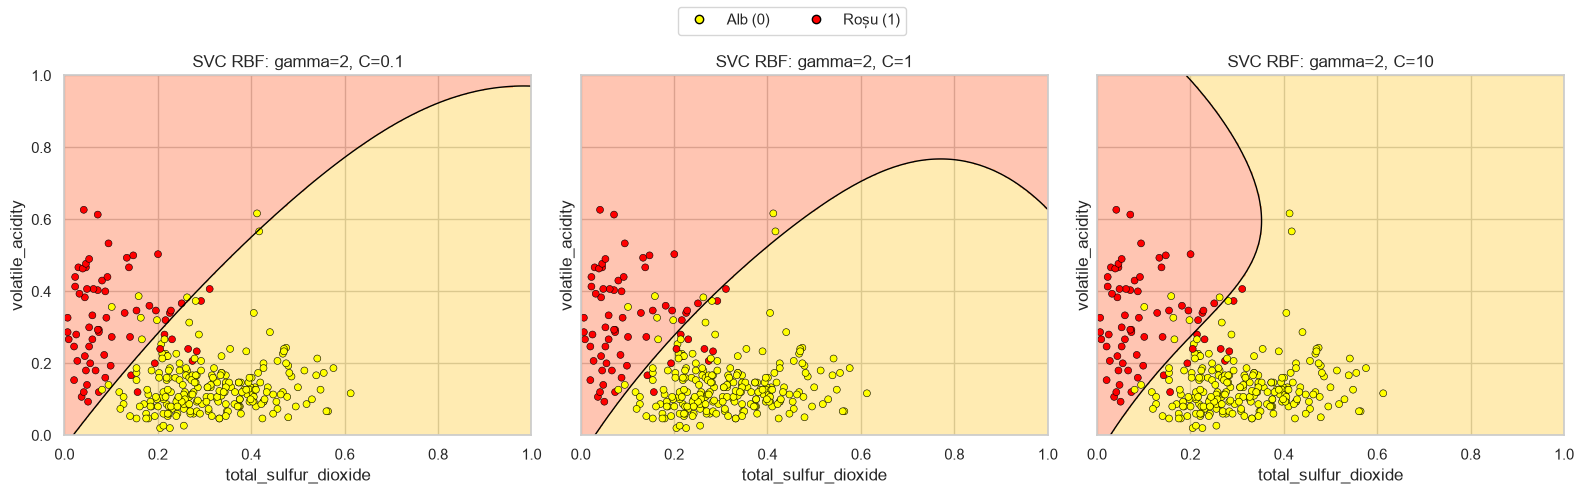

,parametru variat,valoare,acuratețe antrenare,vectori de suport
0,gamma,0.5,0.9554,1067
1,gamma,1.0,0.9547,955
2,gamma,2.0,0.9547,877
3,gamma,10.0,0.9551,775
4,C,0.1,0.9540,1310
5,C,1.0,0.9547,877
6,C,10.0,0.9551,781


In [7]:
Cs = [0.1, 1, 10]
fixed_gamma = 2
c_models = {}
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharex=True, sharey=True)
for ax, C in zip(axes, Cs):
    c_models[C] = plot_decision_boundary(
        SVC(kernel='rbf', gamma=fixed_gamma, C=C), X, y, ax=ax,
        title=f'SVC RBF: gamma={fixed_gamma}, C={C}')
fig.legend(handles=class_legend, loc='upper center', ncol=2)
fig.tight_layout(rect=(0, 0, 1, 0.93))
plt.show()
rows = []
for parameter, models in [('gamma', gamma_models), ('C', c_models)]:
    for value, model in models.items():
        rows.append({'parametru variat': parameter, 'valoare': value,
                     'acuratețe antrenare': model.score(X, y),
                     'vectori de suport': int(model.n_support_.sum())})
display(pd.DataFrame(rows).round(4))

**Interpretare.** Nucleul gaussian este
$K(x,z)=\exp(-\gamma\lVert x-z\rVert^2)$.
Un `gamma` mic produce o influență mai largă a fiecărui exemplu, iar un `gamma`
mare produce o influență locală și poate permite frontiere mai complexe.
`C` controlează penalizarea erorilor și a încălcării marginilor, la `gamma=2`
constant. Valorile mari pot favoriza supraînvățarea, dar aceasta nu se poate
diagnostica doar din scorul de antrenare. În fiecare panou sunt afișate
aceleași 300 de observații; modelele sunt antrenate pe toate datele.

## Întrebarea 4

În această întrebare vom compara timpul de execuție între SVC și Nystroem cu nucleul rbf.
<br><br>
Jupyter Notebooks oferă o funcție magică utilă, **`%timeit`**, care execută un șir de comandă și afișează timpul necesar pentru execuție. Dacă introduceți **`%timeit`** la începutul unei celule, aceasta va rula întreaga celulă și va afișa timpul de execuție.

* Reîncărcați datele privind calitatea vinului dacă ați adus modificări la original.
* Creați variabila `y` din coloana `data.color` și `X` din celelalte coloane.
* Folosiți `%%timeit` pentru a măsura timpul necesar configurării SVC cu nucleul RBF.
* Folosiți `%%timeit` pentru a măsura timpul necesar următoarei operațiuni: ordonați datele folosind Nystroem, apoi integrați clasificatorul SGD.

Nystroem+SGD va necesita mult mai puțin timp pentru antrenare. Această diferență va fi mai pronunțată dacă setul de date ar fi mai mare.

* Faceți 5 copii ale lui X și corelați-le
* Faceți 5 copii ale lui y și corelați-le
* Comparați timpul necesar pentru antrenarea ambelor metode de mai sus.

### Protocolul comparației
Reîncărcăm datele și folosim toate cele 12 coloane numerice, fără `color`.
Aplicăm aceeași scalare MinMax ambelor metode, înainte de cronometrare.
Fixăm `gamma=1/12`, `C=1`, 100 de componente Nystroem și sămânța aleatoare.
Nystroem aproximează nucleul RBF; SGD învață un separator liniar în spațiul
transformat, cu pierdere hinge.

Fiecare `%%timeit` execută trei repetări, cu o singură antrenare pe repetare
și estimator nou. Limităm paralelismul numeric la un fir pentru ambele metode.
Timpul include construirea și antrenarea estimatorului, inclusiv transformarea
Nystroem. Încărcarea, scalarea și concatenarea sunt în afara cronometrării.
`%%timeit` măsoară întreaga celulă, iar `%timeit` o singură instrucțiune.

In [8]:
X_2d, y_2d = X.copy(), y.copy()
data_timing = pd.read_csv(DATA_PATH)
y = data_timing['color'].map({'red': 1, 'white': 0}).astype('int64').rename('y')
X_all_raw = data_timing.drop(columns='color')
timing_scaler = MinMaxScaler()
X = pd.DataFrame(timing_scaler.fit_transform(X_all_raw), columns=X_all_raw.columns)
benchmark_gamma = 1.0 / X.shape[1]

def make_exact_svc():
    return SVC(kernel='rbf', gamma=benchmark_gamma, C=1.0, cache_size=200)

def make_approx_svc():
    return make_pipeline(
        Nystroem(kernel='rbf', gamma=benchmark_gamma, n_components=100, random_state=RANDOM_STATE),
        SGDClassifier(loss='hinge', alpha=0.0001, max_iter=5000,
                      tol=0.0001, random_state=RANDOM_STATE),
    )

X_5 = pd.concat([X] * 5, ignore_index=True)
y_5 = pd.concat([y] * 5, ignore_index=True)
assert len(X_5) == len(y_5) == 5 * len(X)
assert X_5.index.equals(y_5.index)
for start in range(0, len(X_5), len(X)):
    assert np.array_equal(X_5.iloc[start:start + len(X)], X)
    assert np.array_equal(y_5.iloc[start:start + len(y)], y)
print(f'Original: X={X.shape}, y={y.shape}')
print(f'Concatenat de 5 ori: X_5={X_5.shape}, y_5={y_5.shape}')
print(f'Gamma comun: {benchmark_gamma:.6f}')

Original: X=(6497, 12), y=(6497,)
Concatenat de 5 ori: X_5=(32485, 12), y_5=(32485,)
Gamma comun: 0.083333


### SVC RBF — setul original

In [9]:
%%timeit -n 1 -r 3 -o
with threadpool_limits(limits=1):
    make_exact_svc().fit(X, y)

284 ms ± 34.6 ms per loop (mean ± std. dev. of 3 runs, 1 loop each)


<TimeitResult : 284 ms ± 34.6 ms per loop (mean ± std. dev. of 3 runs, 1 loop each)>

In [10]:
# Salvăm TimeitResult returnat de -o și păstrat de IPython în _.
timing_svc = _

### Nystroem + SGD — setul original

In [11]:
%%timeit -n 1 -r 3 -o
with threadpool_limits(limits=1):
    make_approx_svc().fit(X, y)

100 ms ± 5.62 ms per loop (mean ± std. dev. of 3 runs, 1 loop each)


<TimeitResult : 100 ms ± 5.62 ms per loop (mean ± std. dev. of 3 runs, 1 loop each)>

In [12]:
# Salvăm TimeitResult returnat de -o și păstrat de IPython în _.
timing_approx = _

### SVC RBF — cinci copii

In [13]:
%%timeit -n 1 -r 3 -o
with threadpool_limits(limits=1):
    make_exact_svc().fit(X_5, y_5)

5.13 s ± 596 ms per loop (mean ± std. dev. of 3 runs, 1 loop each)


<TimeitResult : 5.13 s ± 596 ms per loop (mean ± std. dev. of 3 runs, 1 loop each)>

In [14]:
# Salvăm TimeitResult returnat de -o și păstrat de IPython în _.
timing_svc_5 = _

### Nystroem + SGD — cinci copii

In [15]:
%%timeit -n 1 -r 3 -o
with threadpool_limits(limits=1):
    make_approx_svc().fit(X_5, y_5)

431 ms ± 4.75 ms per loop (mean ± std. dev. of 3 runs, 1 loop each)


<TimeitResult : 431 ms ± 4.75 ms per loop (mean ± std. dev. of 3 runs, 1 loop each)>

In [16]:
# Salvăm TimeitResult returnat de -o și păstrat de IPython în _.
timing_approx_5 = _

,set,n,metodă,medie (s),deviație standard (s)
0,Original,6497,SVC RBF,0.2836,0.0346
1,Original,6497,Nystroem + SGD,0.1002,0.0056
2,5 copii,32485,SVC RBF,5.1262,0.5964
3,5 copii,32485,Nystroem + SGD,0.4314,0.0047


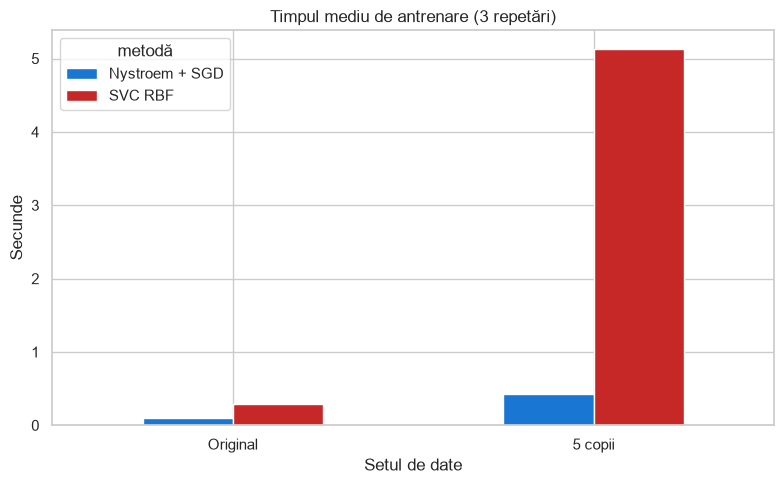

Original: Nystroem + SGD este de 2.83 ori mai rapid în această rulare.
5 copii: Nystroem + SGD este de 11.88 ori mai rapid în această rulare.
Creșterea timpului SVC pentru 5× date: 18.07×
Creșterea timpului Nystroem + SGD pentru 5× date: 4.31×


In [17]:
timing_rows = []
for dataset, n, method, result in [
    ('Original', len(X), 'SVC RBF', timing_svc),
    ('Original', len(X), 'Nystroem + SGD', timing_approx),
    ('5 copii', len(X_5), 'SVC RBF', timing_svc_5),
    ('5 copii', len(X_5), 'Nystroem + SGD', timing_approx_5),
]:
    assert result.loops == 1 and result.repeat == 3
    timing_rows.append({'set': dataset, 'n': n, 'metodă': method,
                        'medie (s)': result.average, 'deviație standard (s)': result.stdev})
timings = pd.DataFrame(timing_rows)
display(timings.round(4))
comparison = timings.pivot(index='set', columns='metodă', values='medie (s)').reindex(['Original', '5 copii'])
ax = comparison.plot.bar(figsize=(8, 5), rot=0, color=['#1976d2', '#c62828'])
ax.set(title='Timpul mediu de antrenare (3 repetări)', xlabel='Setul de date', ylabel='Secunde')
plt.tight_layout()
plt.show()
for dataset, row in comparison.iterrows():
    ratio = row['SVC RBF'] / row['Nystroem + SGD']
    if ratio >= 1:
        print(f'{dataset}: Nystroem + SGD este de {ratio:.2f} ori mai rapid în această rulare.')
    else:
        print(f'{dataset}: SVC este de {1 / ratio:.2f} ori mai rapid în această rulare.')
print(f'Creșterea timpului SVC pentru 5× date: {timing_svc_5.average / timing_svc.average:.2f}×')
print(f'Creșterea timpului Nystroem + SGD pentru 5× date: {timing_approx_5.average / timing_approx.average:.2f}×')

**Interpretare și limite.** Concluzia despre viteză se bazează pe măsurătorile
de mai sus. Pentru 100 de componente fixe, costul transformării Nystroem crește
aproximativ liniar cu numărul de observații. SVC poate scala mai greu.
Pe seturi mici, costurile fixe ale aproximării pot anula avantajul; metoda
Nystroem nu este obligatoriu mai rapidă în orice configurație.

Cele cinci copii sunt identice: cresc volumul de calcul fără să adauge informație
statistică. SVC și SGD nu optimizează exact aceeași problemă; `C` și `alpha`
controlează diferit regularizarea. Comparăm timpul, fără a presupune calitate
predictivă egală. Numărul de componente, `gamma`, toleranța și hardware-ul pot
schimba rezultatele.

### Concluzii
- Cele două variabile selectate sunt dioxidul de sulf total și aciditatea volatilă.
- LinearSVC produce o frontieră liniară, iar nucleul RBF permite frontiere neliniare.
- `gamma` controlează raza influenței; `C` echilibrul între regularizare și erorile de antrenare.
- Nystroem + SGD folosește o aproximare cu dimensiune fixă, al cărei avantaj de timp trebuie măsurat.